<a href="https://colab.research.google.com/github/Twishha-Soni/MakeMore/blob/main/MakeMore_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Makemore: part 3

In [1]:
import torch
import torch.nn.functional as F
import random
random.seed(42)
import matplotlib.pyplot as plt
%matplotlib inline

Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


In [2]:
# read in all the words and store them in data structure
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [3]:
len(words)

32033

In [4]:
# building the vocabulary of characters and mappings to/from integers
chars = sorted(list(set("".join(words))))
stoi = {s:i for i,s in enumerate(chars, start=1)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
vocab_size

27

In [16]:
# Build the dataset for MLP
block_size = 3   # context length: how many characters do we take to predict the next character

def build_dataset(words):
  X, Y = [], []

  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix]

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y


# Split the dataset in train, dev and test set
# 80% - 10% - 10%
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182383, 3]) torch.Size([182383])
torch.Size([22907, 3]) torch.Size([22907])
torch.Size([22856, 3]) torch.Size([22856])


In [59]:
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd), generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * 0.1
b1 = torch.randn(n_hidden, generator=g) * 0.01
W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01
b2 = torch.randn(vocab_size, generator=g) * 0

parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters))
for p in parameters:
  p.requires_grad = True


11897


In [60]:
# same optimization as the last time
max_steps = 2_00_000
batch_size = 32
lossi = []

for i in range(max_steps):

  # mini-batch contruct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix]   # batch X, Y

  # forward pass
  emb = C[Xb]  # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  hpreact = embcat @ W1 + b1 # hidden layer pre-activation
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb)  # loss function - (-loglikelihood/n)

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i < 1_00_000 else 0.01   # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10_000 == 0:
    print(f"{i:7d}/{max_steps:7d}: {loss.item():.4f}")
  lossi.append(loss.log10().item())

  # break

      0/ 200000: 3.2930
  10000/ 200000: 2.2651
  20000/ 200000: 2.2631
  30000/ 200000: 2.4706
  40000/ 200000: 1.8286
  50000/ 200000: 2.0488
  60000/ 200000: 1.5552
  70000/ 200000: 2.3682
  80000/ 200000: 1.9780
  90000/ 200000: 2.1328
 100000/ 200000: 2.3792
 110000/ 200000: 1.8242
 120000/ 200000: 1.8145
 130000/ 200000: 1.9744
 140000/ 200000: 1.9829
 150000/ 200000: 1.9664
 160000/ 200000: 1.7111
 170000/ 200000: 2.3856
 180000/ 200000: 1.8346
 190000/ 200000: 1.6801


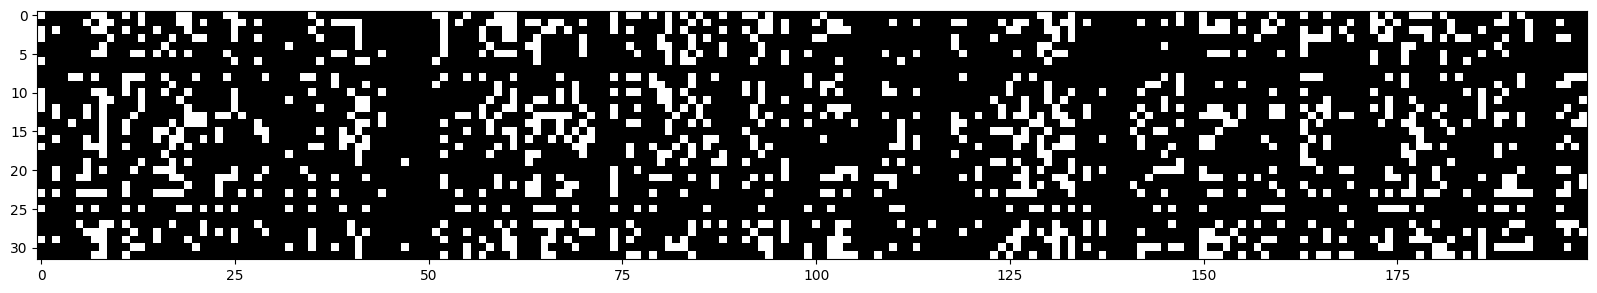

In [61]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs() > 0.99, cmap='gray', interpolation='nearest')

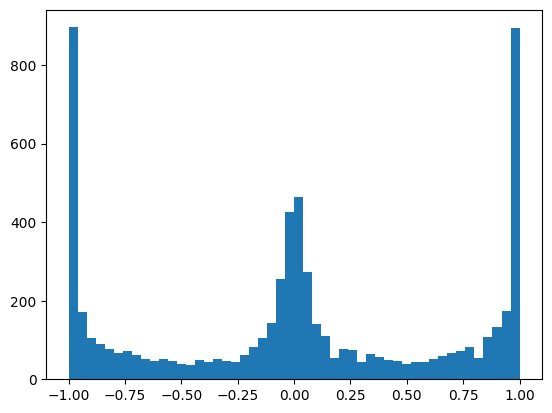

In [62]:
plt.hist(h.view(-1).tolist(),50);

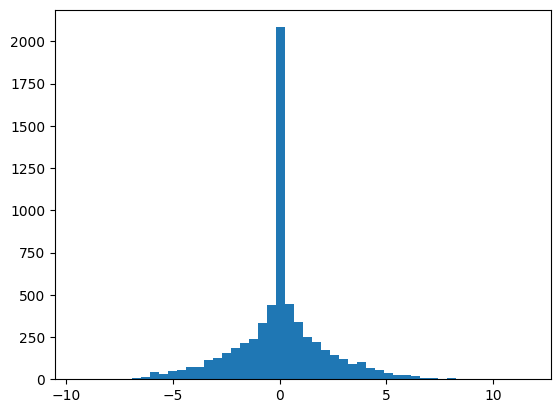

In [63]:
plt.hist(hpreact.view(-1).tolist(), 50);

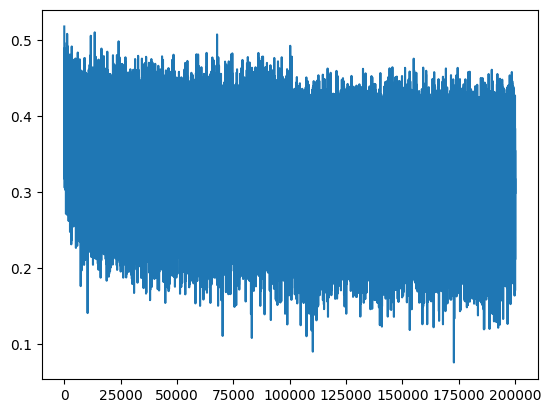

In [64]:
plt.plot(lossi)

In [65]:
@torch.no_grad()   # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
      'train': (Xtr, Ytr),
      'val': (Xdev, Ydev),
      'test': (Xte, Yte),
  }[split]

  emb = C[x]   # (N, block_size, n_embd)
  # C - (27, 10)   x - (38493, 3)
  embcat = emb.view(emb.shape[0], -1)
  h = torch.tanh(embcat @ W1 + b1)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.0599353313446045
val 2.1122498512268066


In [67]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):

  out = []
  context = [0] * block_size
  while True:
    # forward pass the neural net
    emb = C[torch.tensor([context])]   # (1, block_size, n_embd)
    h = torch.tanh(emb.view(1, -1) @ W1 + b1)
    logits = h @ W2 + b2
    probs = F.softmax(logits, dim=1)

    # sample from the distribution
    ix = torch.multinomial(probs, num_samples=1, generator=g).item()

    # shift the context window and track the samples
    context = context[1:] + [ix]
    out.append(ix)

    # if we sample the special '.' token, break
    if ix == 0:
      break

  print(''.join(itos[i] for i in out))

carmah.
amorie.
khi.
milia.
aty.
skanden.
jazhunna.
perric.
kaeli.
ner.
kiah.
maiivia.
leigh.
ham.
join.
quintis.
lilea.
jadbi.
watell.
dearynn.
